[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_symmtop.ipynb)


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

# Symmetric top

Euler’s equations are nonlinear. Under a general external torque, rigid-body motion cannot usually be integrated by quadratures. Torque-free motion is integrable, although elliptic functions are needed in the asymmetric case:

In [2]:
t=sp.symbols('t',real=True)
i1,i2,i3=sp.symbols('I_1 I_2 I_3',positive=True)
inrt=sp.diag(i1,i2,i3)
om=sp.Matrix([sp.Function(f'Omega_{j}')(t) for j in range(1,4)])
mom=inrt*om
eulereq=[sp.Eq(lhs,0) for lhs in sp.diff(mom,t)+om.cross(mom)]
display(*eulereq)

Eq(I_1*Derivative(Omega_1(t), t) - I_2*Omega_2(t)*Omega_3(t) + I_3*Omega_2(t)*Omega_3(t), 0)

Eq(I_1*Omega_1(t)*Omega_3(t) + I_2*Derivative(Omega_2(t), t) - I_3*Omega_1(t)*Omega_3(t), 0)

Eq(-I_1*Omega_1(t)*Omega_2(t) + I_2*Omega_1(t)*Omega_2(t) + I_3*Derivative(Omega_3(t), t), 0)

In [3]:
# A branch-explicit quadrature replaces the source's inverse-function solution.
# Signs are continued through turning points; principal-axis equilibria are separate.
E,M,s,s0,t0=sp.symbols('E M s s_0 t_0',real=True)
X,Z=sp.symbols('X Z')
squares=sp.solve([i1**2*X+i2**2*s**2+i3**2*Z-M**2,
                  i1*X+i2*s**2+i3*Z-2*E],(X,Z))
P=sp.factor(((i3-i1)/i2)**2*squares[X]*squares[Z])
quadrature=sp.Eq(t-t0,sp.Integral(1/sp.sqrt(P),(s,s0,om[1])))
display(quadrature,sp.Eq(om[0]**2,squares[X].subs(s,om[1])),
        sp.Eq(om[2]**2,squares[Z].subs(s,om[1])))
# Reversing the sign of sqrt(P) selects the opposite monotone branch.
# Distinct principal moments are assumed here; symmetric tops follow below.

Eq(t - t_0, Integral(sqrt(I_1)*I_2*sqrt(I_3)/sqrt((-2*E*I_1 + I_1*I_2*s**2 - I_2**2*s**2 + M**2)*(2*E*I_3 + I_2**2*s**2 - I_2*I_3*s**2 - M**2)), (s, s_0, Omega_2(t))))

Eq(Omega_1(t)**2, (-2*E*I_3 - I_2**2*Omega_2(t)**2 + I_2*I_3*Omega_2(t)**2 + M**2)/(I_1**2 - I_1*I_3))

Eq(Omega_3(t)**2, (2*E*I_1 - I_1*I_2*Omega_2(t)**2 + I_2**2*Omega_2(t)**2 - M**2)/(I_1*I_3 - I_3**2))

The solution in quadratures is possible because angular momentum magnitude and kinetic energy are conserved:

In [4]:
w=sp.Matrix(sp.symbols('w_1:4',real=True)); w_initial=sp.Matrix(sp.symbols('w_10 w_20 w_30',real=True))
rhs=-inrt.inv()*w.cross(inrt*w)
M_squared=(inrt*w).dot(inrt*w); twice_energy=w.dot(inrt*w)
for invariant in (M_squared,twice_energy):
    assert sp.simplify(sum(sp.diff(invariant,w[j])*rhs[j] for j in range(3)))==0
display((inrt*w_initial).dot(inrt*w_initial),w_initial.dot(inrt*w_initial))

I_1**2*w_10**2 + I_2**2*w_20**2 + I_3**2*w_30**2

I_1*w_10**2 + I_2*w_20**2 + I_3*w_30**2

These two conservation laws reduce the three coupled equations to one:

In [5]:
display({sp.Symbol('Omega_1_squared'):sp.factor(squares[X].subs(s,om[1])),
         sp.Symbol('Omega_3_squared'):sp.factor(squares[Z].subs(s,om[1]))})

{Omega_1_squared: -(2*E*I_3 + I_2**2*Omega_2(t)**2 - I_2*I_3*Omega_2(t)**2 - M**2)/(I_1*(I_1 - I_3)),
 Omega_3_squared: (2*E*I_1 - I_1*I_2*Omega_2(t)**2 + I_2**2*Omega_2(t)**2 - M**2)/(I_3*(I_1 - I_3))}

Additional symmetry, such as $I_1=I_2$, simplifies the motion further and gives the following equation:

$$
\frac{{d\omega }_{2}}{dt}=A\left(a-{\omega }_{2}^{2}\right)\left(b-{\omega }_{2}^{2}\right)\Rightarrow  t =A {\int }_{0}^{\omega }\frac{dx}{\sqrt{\left(1-{k}^{2}{x}^{2}\right)\left(1-{x}^{2}\right)}}\tag{1}
$$

Jacobi elliptic functions generalize the trigonometric sine and cosine. Their geometric motivation involves an ellipse with eccentricity $k$:

$$
{\left(\frac{x}{a}\right)}^{2}+{\left(\frac{y}{b}\right)}^{2}=1, \\ a>b,k=\sqrt{1-{\left(b/a\right)}^{2}}\\ cn\left(u,k\right)=x/a, y/b=sn\left(u,k\right)\tag{2}
$$

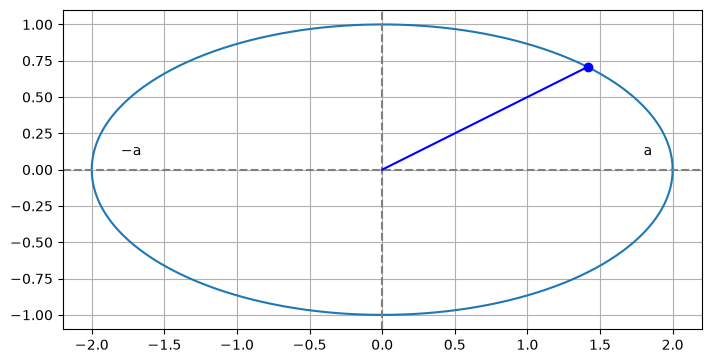

In [6]:
q=np.linspace(0,2*np.pi,500)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.plot(2*np.cos(q),np.sin(q)); ax.axhline(0,ls='--',color='gray'); ax.axvline(0,ls='--',color='gray')
point=[2*np.cos(np.pi/4),np.sin(np.pi/4)]
ax.plot([0,point[0]],[0,point[1]],'b-'); ax.plot(*point,'bo')
ax.text(1.8,.1,'a'); ax.text(-1.8,.1,'−a'); ax.set(aspect='equal'); ax.grid(); plt.show()

To motivate an analogue of the circular angle, first consider the scaled arc length of an ellipse:

$$
j\left(\varphi \right) = {\int }_{0}^{\varphi }\frac{dl}{a}={\int }_{0}^{\varphi }\sqrt{1-{k}^{2}\sin^{2}{t}}dt\tag{3}
$$

and its derivative

$$
\frac{dj}{d\varphi } =\sqrt{1-{k}^{2}\sin^{2}{\varphi} }\tag{4}
$$

In terms of the angular parameter $\varphi$, we can write

$$
cn\left(u,k\right)=\cos{\varphi} ,sn\left(u,k\right)=\sin{\varphi}\tag{5}
$$

Now the angles in (4) we may interpret in inverse manner and define

$$
\frac{d\varphi }{du}=\sqrt{1-{k}^{2}\sin^{2}{\varphi} }\Rightarrow u={\int }_{0}^{\varphi }\frac{dt}{\sqrt{1-{k}^{2}\sin^{2}{t}}}\tag{6}
$$

Traditionally (4) denoted as (d is not differential!)

$$
dn\left(u,k\right)\Rightarrow {dn}^{2}+{k}^{2}{sn}^{2}\left(u,k\right)=1\tag{7}
$$

The angle $\varphi=\operatorname{am}\left(u,k\right)$ is called the Jacobi amplitude.

## Euler case

The simplest case is a symmetric top fixed at its centre of mass, so gravity exerts no torque about the fixed point. Kinetic energy and angular momentum are conserved. Recall Poinsot’s representation of free rotation:



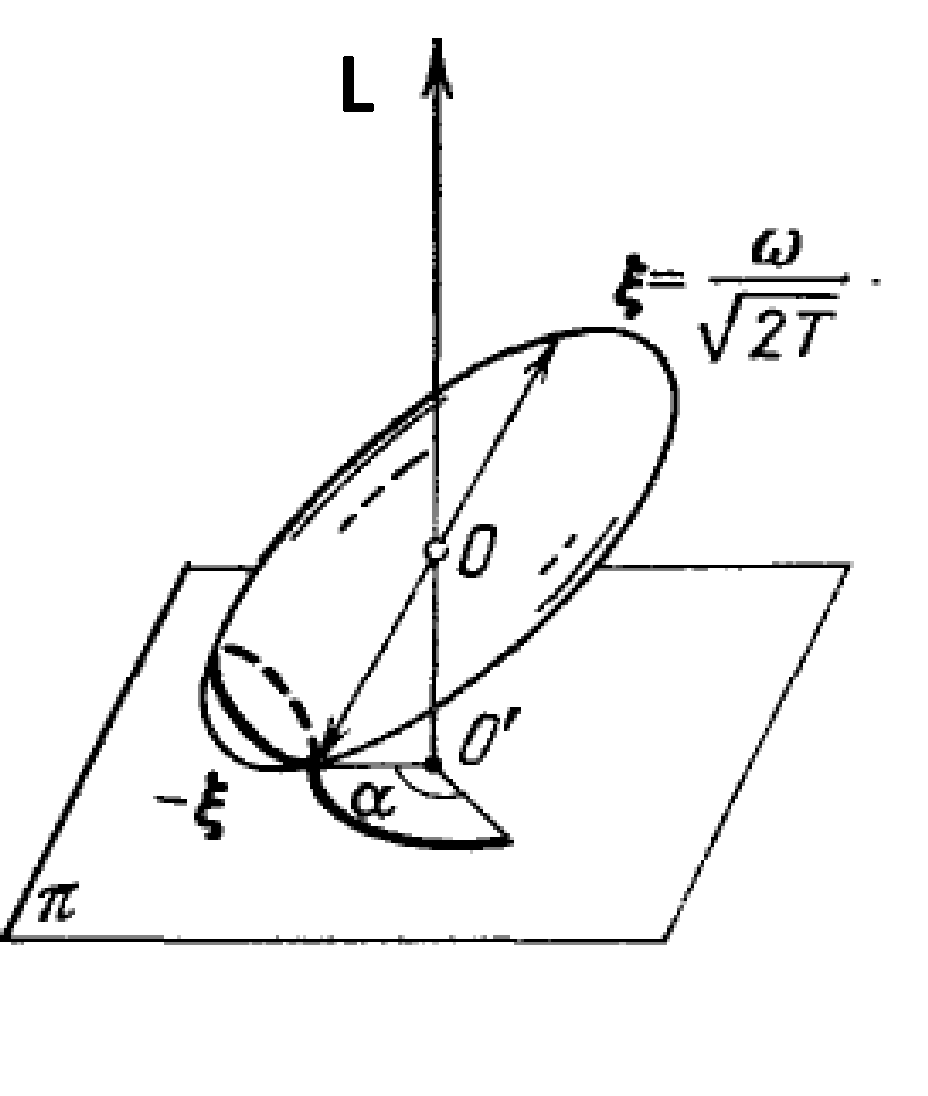


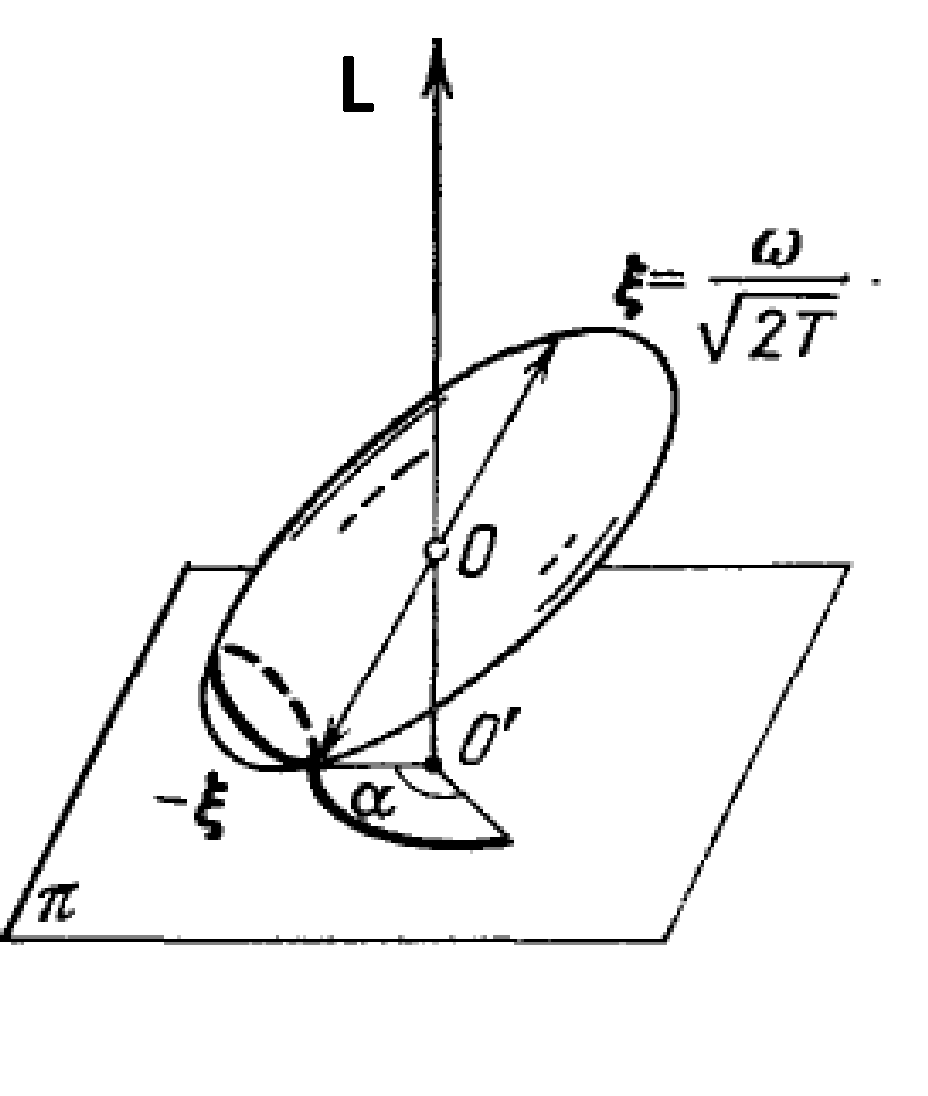

The rotation axis precesses around the angular momentum direction, chosen as the Z axis, while the inertia ellipsoid rolls along a circle.

Recall the geometry of Euler’s angles:



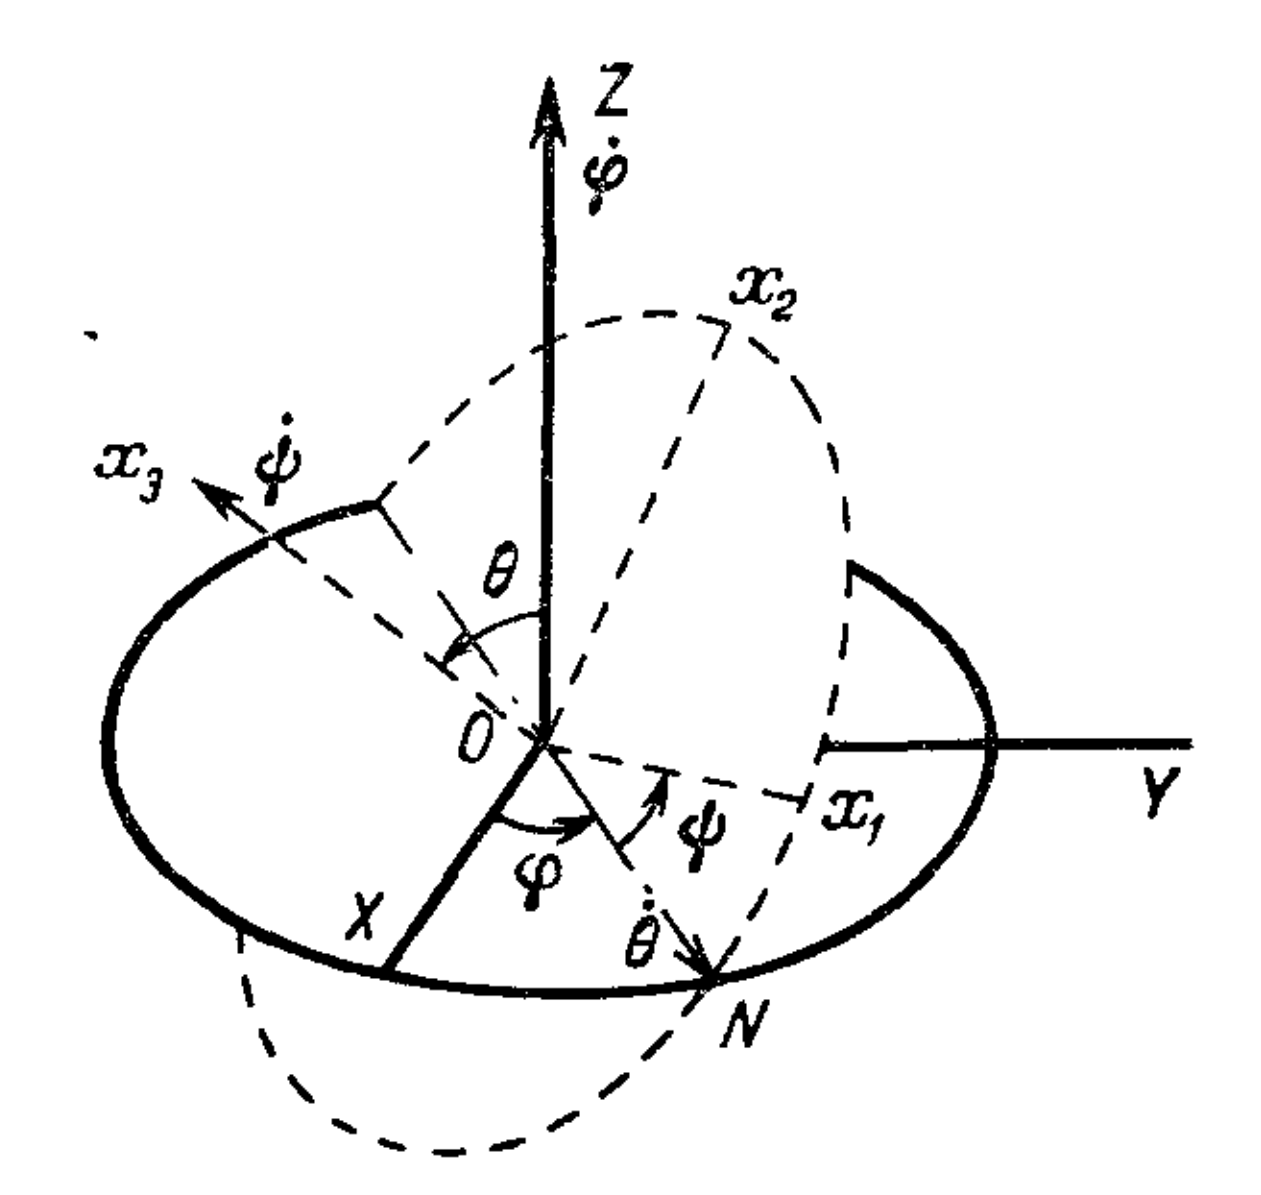


Fig. Euler’s angles. N  is the node axis as the intersection of XY and x1x2 planes
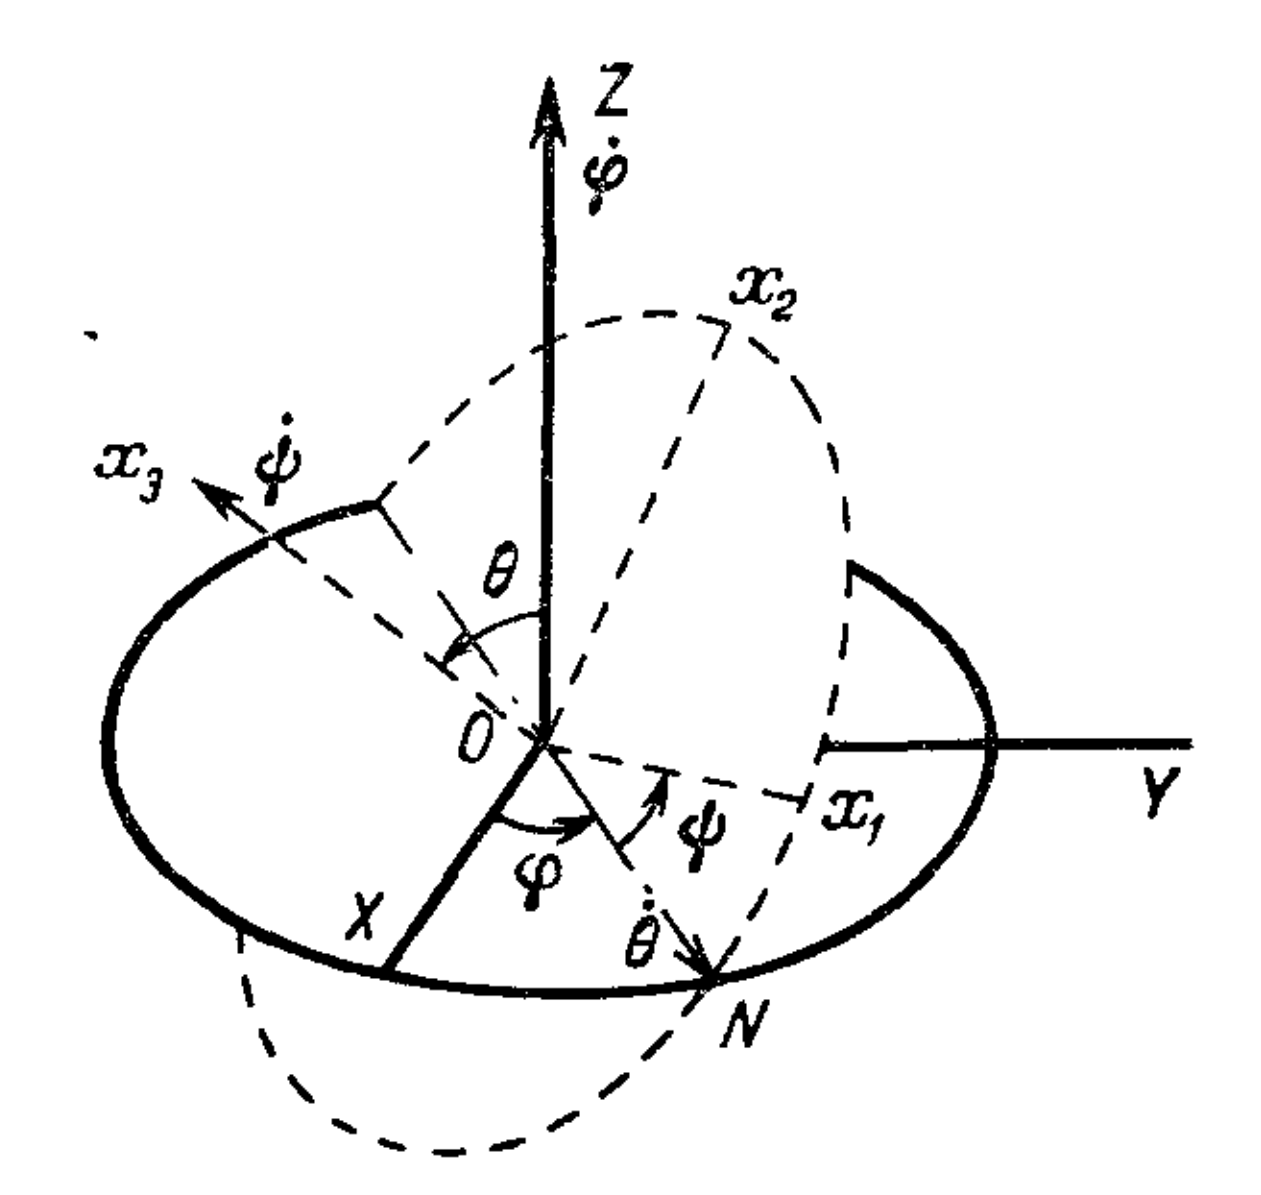

and angular velocity of rotation

$$
\mathbf{\omega } = \dot{\varphi } \mathbf{k}\mathbf{+}\dot{\theta } {\mathbf{e}}_{N}+\dot{\psi } {\mathbf{e}}_{3}
$$

in body-fixed reference

$$
\mathbf{\Omega }\mathbf{ }\mathbf{=}\left(\dot{\varphi }\sin{\psi}  \sin{\theta} +\dot{\theta }\cos{\psi} \right){\mathbf{e}}_{1}+\left(\dot{\varphi }\cos{\psi}  \sin{\theta} -\dot{\theta }\sin{\psi} \right){\mathbf{e}}_{2}+\mathbf{ }\left(\dot{\varphi } \cos{\theta} +\dot{\psi }\right){\mathbf{e}}_{3}
$$

The Lagrangian is therefore:

$$
L = \frac{{I}_{1}}{2}\left({\Omega }_{1}^{2}+{\Omega }_{2}^{2}\right)+\frac{{I}_{3}}{2}{\Omega }_{3}^{2}=\frac{{I}_{1}}{2}\left({\dot{\theta }}^{2}+{\dot{\varphi }}^{2}\sin^{2}{\theta}  \right)+\frac{{I}_{3}}{2}{\left(\cos{\theta} \dot{\varphi }+\dot{\psi }\right)}^{2}
$$

Euler’s equations are:

$$
\frac{d {\mathbf{\Omega }}_{1}}{dt}=\left(1-{I}_{3}/{I}_{1}\right){\Omega }_{2}{\Omega }_{3}\\ \frac{d {\mathbf{\Omega }}_{2}}{dt}=\left({I}_{3}/{I}_{1}-1\right){\Omega }_{3}{\Omega }_{1}\\ {I}_{3}\frac{d {\mathbf{\Omega }}_{3}}{dt}=0\Rightarrow {\Omega }_{3}=\text{const}
$$

$$
\frac{d }{dt}\left({\mathbf{\Omega }}_{1}+{\mathrm{i}\mathbf{\Omega }}_{2}\right)=\mathrm{i} {\omega }_{0}\left({\Omega }_{1}+{\mathrm{i}\mathbf{\Omega }}_{2}\right)\Rightarrow \left({\mathbf{\Omega }}_{1}+{\mathrm{i}\mathbf{\Omega }}_{2}\right)=W {e}^{\mathrm{i} {\omega }_{0} t}\\ {\omega }_{0}=\left({I}_{3}/{I}_{1}-1\right){\Omega }_{3}
$$

With corresponding initial conditions we have

$$
{\Omega }_{1}=W \cos{{\omega }_{0} t}, {\Omega }_{2}=W \sin{{\omega }_{0} t}
$$

This means that vector  Ω precesses around ${I}_{3}$-axis with angular velocity ${\omega }_{0}$. 

With no friction at the fixed point, the following quantities are conserved:

$$
L=\text{const}, \frac{\partial  L}{\partial  \varphi }=\frac{\partial  L}{\partial  \psi }=0\Rightarrow \\ \frac{\partial  L}{\partial  \dot{\psi }}={M}_{3}={I}_{3}\left(\cos{\theta} \dot{\varphi }+\dot{\psi }\right)=\text{const},\frac{\partial  L}{\partial  \dot{\varphi }}={I}_{1}\dot{\varphi } \sin^{2}{\theta} +{M}_{3}\cos{\theta}  ={M}_{z}=\text{const}
$$

Since ${M}^{2}={M}_{1}^{2}+{M}_{2}^{2}+{M}_{3}^{2}=\text{const}$ and ${M}_{3}={I}_{3}{\Omega }_{3}=M \cos{\theta} $ then θ = ${\theta }_{0}$ and $\dot{\varphi }=\frac{\left|\mathbf{M}\right|}{{I}_{1}}$, $\dot{\psi }$ are also constants

## Lagrange heavy top case

Let’s apply the Euler’s angles to the motion of heavy symmetrical $\left({I}_{1}={I}_{2}\ne {I}_{3}\right)$ top with fixed point 


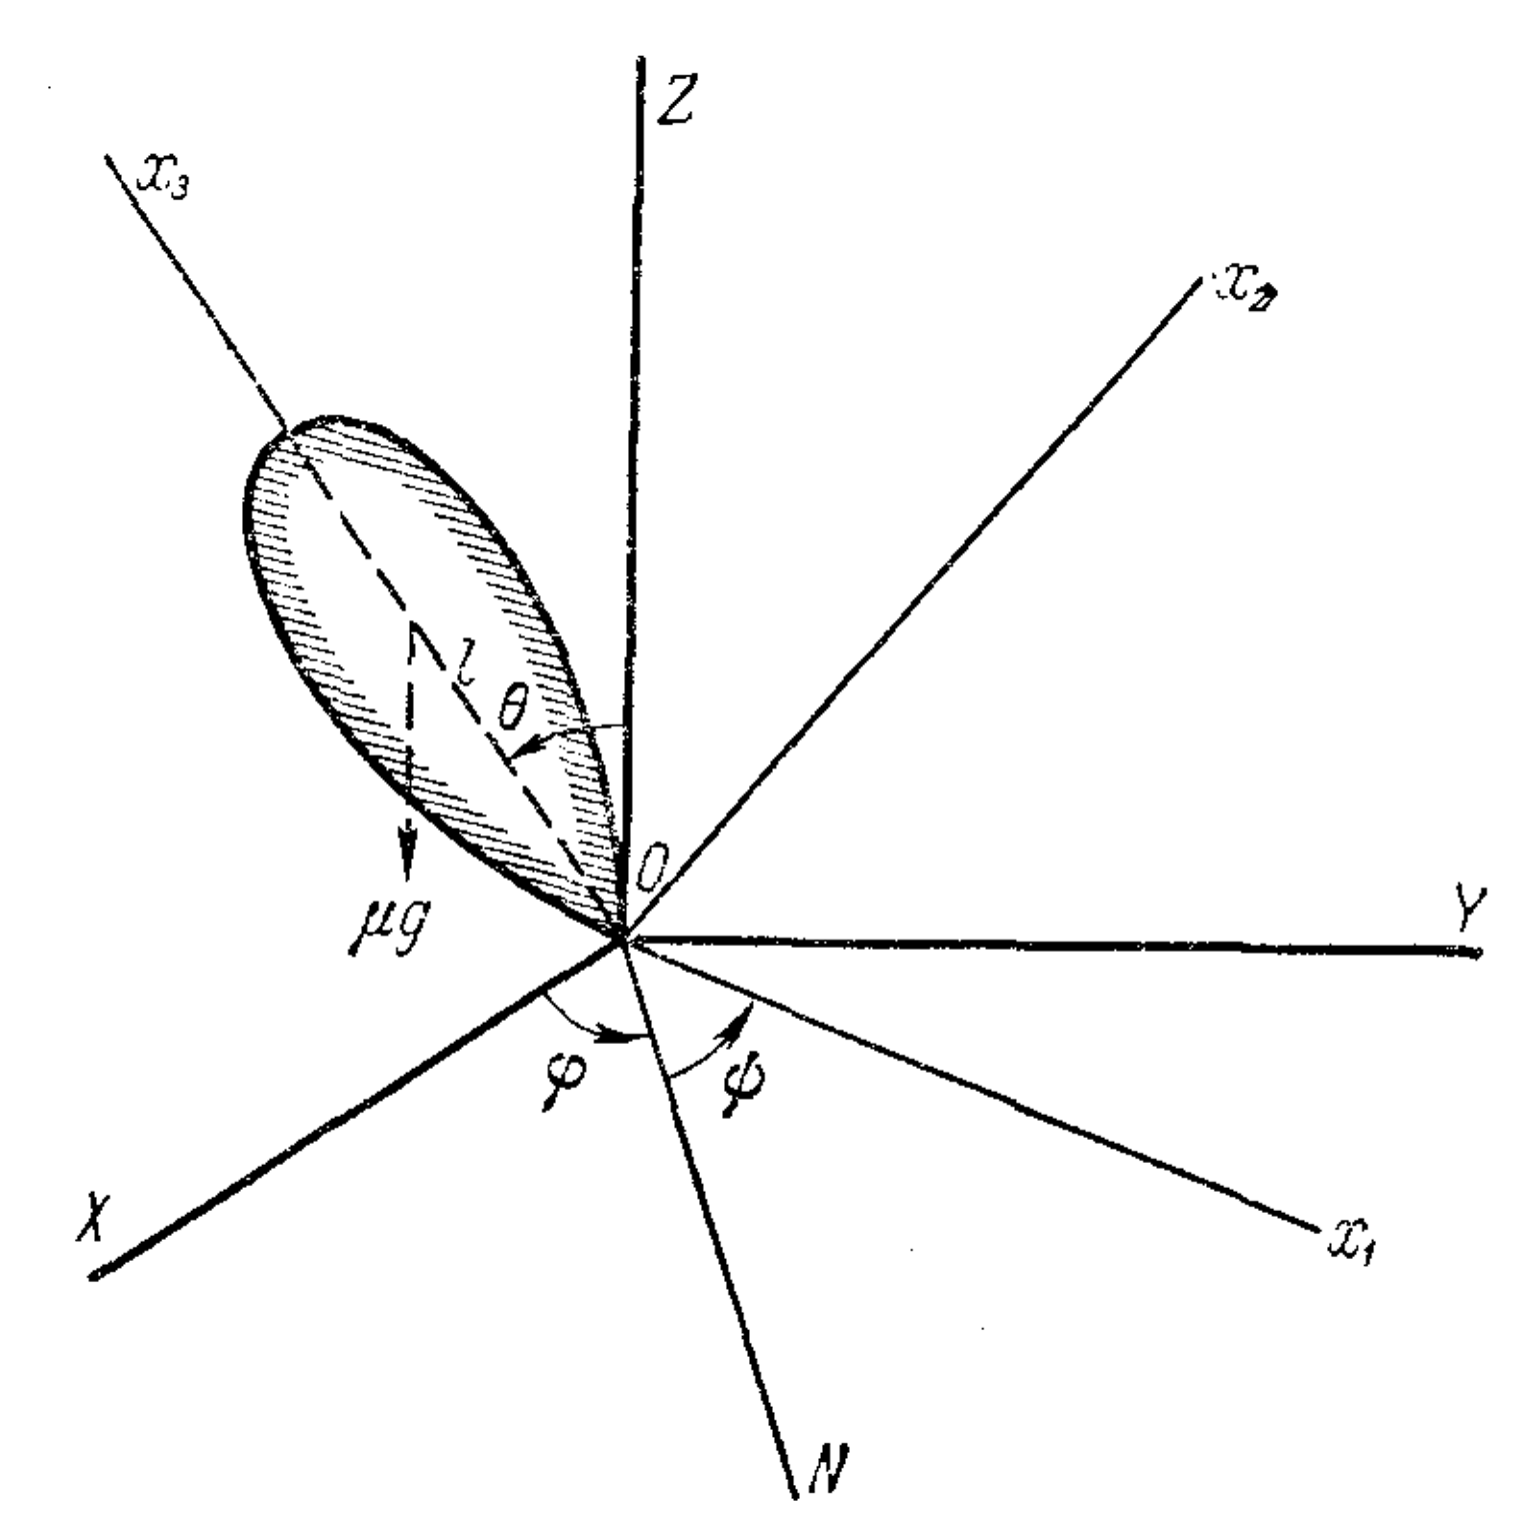


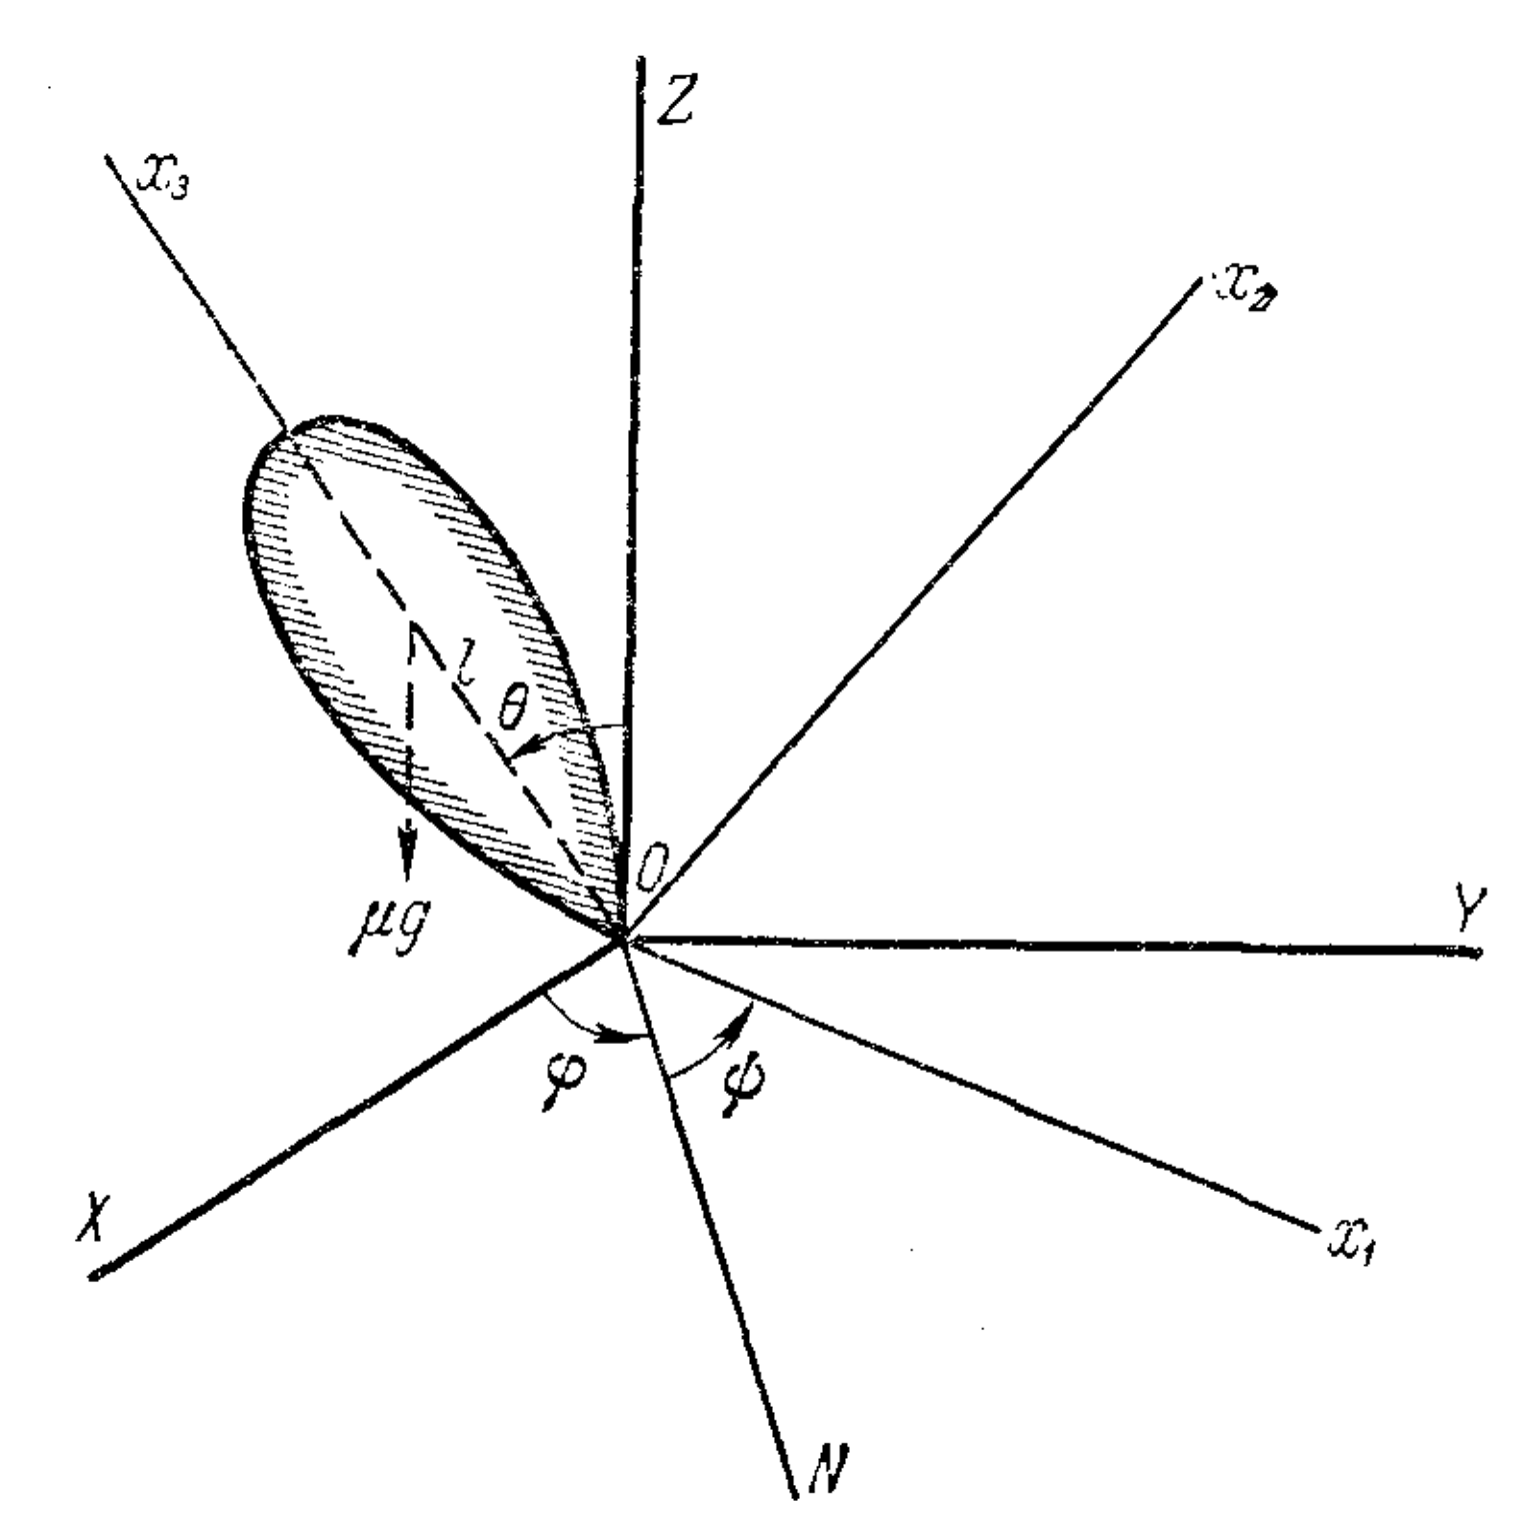

Recall that vector Ω in body-reference system according to definition is:

$$
\frac{d\mathbf{r}}{dt}=\frac{dR}{dt}\mathbf{q}\mathbf{\Rightarrow }{R}^{T}\frac{d\mathbf{r}}{dt}={R}^{T}\frac{dR}{dt}\mathbf{q}\mathbf{=}\mathbf{\Omega \times q\Rightarrow \Omega }\mathbf{ }\mathbf{=}\mathbf{ }{R}^{T}\mathbf{ }\mathbf{\omega }
$$

with the components in a body reference system:

$$
\mathbf{\Omega }\mathbf{ }\mathbf{=}\left(\dot{\varphi }\sin{\psi}  \sin{\theta} +\dot{\theta }\cos{\psi} \right){\mathbf{e}}_{1}+\left(\dot{\varphi }\cos{\psi}  \sin{\theta} -\dot{\theta }\sin{\psi} \right){\mathbf{e}}_{2}+\mathbf{ }\left(\dot{\varphi } \cos{\theta} +\dot{\psi }\right){\mathbf{e}}_{3}
$$

In [7]:
theta,psi,theta1,phi1,psi1=sp.symbols('theta psi theta_dot varphi_dot psi_dot',real=True)
transverse=(sp.cos(psi)*theta1+sp.sin(theta)*sp.sin(psi)*phi1)**2+(-sp.sin(psi)*theta1+sp.cos(psi)*sp.sin(theta)*phi1)**2
display(sp.trigsimp(sp.expand(transverse)))

theta_dot**2 + varphi_dot**2*sin(theta)**2

The Lagrangian is therefore:

$$
L = \frac{{\widetilde{I}}_{1}}{2}\left({\Omega }_{1}^{2}+{\Omega }_{2}^{2}\right)+\frac{{I}_{3}}{2}{\Omega }_{3}^{2}-m g l \cos{\theta} =\frac{{\widetilde{I}}_{1}}{2}\left({\dot{\theta }}^{2}+{\dot{\varphi }}^{2}\sin^{2}{\theta}  \right)+\frac{{I}_{3}}{2}{\left(\cos{\theta} \dot{\varphi }+\dot{\psi }\right)}^{2}-m g l \cos{\theta}
$$

Here we use

$$
{\widetilde{I}}_{1}={I}_{1}+m {l}^{2}
$$

because the fixed point lies a distance $l$ from the centre of mass (the parallel-axis theorem).

With no friction at the fixed point, energy $E$ and the following generalized momenta are conserved:

$$
\frac{\partial  L}{\partial  \varphi }=\frac{\partial  L}{\partial  \psi }=0\Rightarrow \frac{\partial  L}{\partial  \dot{\psi }}={I}_{3}\left(\cos{\theta} \dot{\varphi }+\dot{\psi }\right)={M}_{3}=\text{const}\\ \frac{\partial  L}{\partial  \dot{\varphi }}={\widetilde{I}}_{1}\dot{\varphi }\sin^{2}{\theta} +{M}_{3}\cos{\theta}  ={M}_{z}=\text{const}
$$

This reduces the dynamics to the single angle $\theta$.

In [8]:
omega0,mz,m3=sp.symbols('omega_0 M_z M_3',real=True)
kinetic=i1/2*(theta1**2+phi1**2*sp.sin(theta)**2)+i3/2*(sp.cos(theta)*phi1+psi1)**2
lagr=kinetic-omega0**2*sp.cos(theta); enrg=kinetic+omega0**2*sp.cos(theta)
rates=sp.solve([sp.diff(lagr,phi1)-mz,sp.diff(lagr,psi1)-m3],(phi1,psi1))
reduced_energy=sp.trigsimp(enrg.subs(rates))
display(rates,reduced_energy)

{psi_dot: M_3/I_3 + M_3*cos(theta)**2/(I_1*sin(theta)**2) - M_z*cos(theta)/(I_1*sin(theta)**2),
 varphi_dot: -M_3*cos(theta)/(I_1*sin(theta)**2) + M_z/(I_1*sin(theta)**2)}

I_1*(theta_dot**2 + (-M_3*cos(theta) + M_z)**2/(I_1**2*sin(theta)**2))/2 + omega_0**2*cos(theta) + M_3**2/(2*I_3)

$$
E =\frac{{\widetilde{I}}_{1}}{2}\left({\dot{\theta }}^{2}+{\dot{\varphi }}^{2}\sin^{2}{\theta}  \right)+\frac{{I}_{3}}{2}{\left(\cos{\theta} \dot{\varphi }+\dot{\psi }\right)}^{2}+m g l \cos{\theta} =\frac{{M}_{3}^{2}}{2{I}_{3}}+\frac{{\widetilde{I}}_{1}{\dot{\theta }}^{2}}{2}+m {l}^{2}{\omega }_{0}^{2} \cos{\theta} +\frac{{\left({M}_{3} \cos{\theta} -{M}_{z} \right)}^{2}}{2{\widetilde{I}}_{1}\sin^{2}{\theta} }
$$

The behaviour near $\theta=0$ is governed by the effective potential below. The upright configuration requires compatible conserved momenta; its stability also depends on the spin.

$$
{U}_{\text{eff}}\left(\theta \right)=-m {l}^{2}{\omega }_{0}^{2} \left(1-\cos{\theta} \right)+\frac{{\left({M}_{3} \cos{\theta} -{M}_{z} \right)}^{2}}{2{\widetilde{I}}_{1}\sin^{2}{\theta} }\\ \dot{\theta }=\pm \sqrt{\frac{2}{\widetilde{{I}_{1}}}\left(\widetilde{E}-{U}_{\text{eff}}\left(\theta \right)\right)}
$$

For bounded nutation, $\theta$ lies between turning angles $\theta_{\min}$ and $\theta_{\max}$.

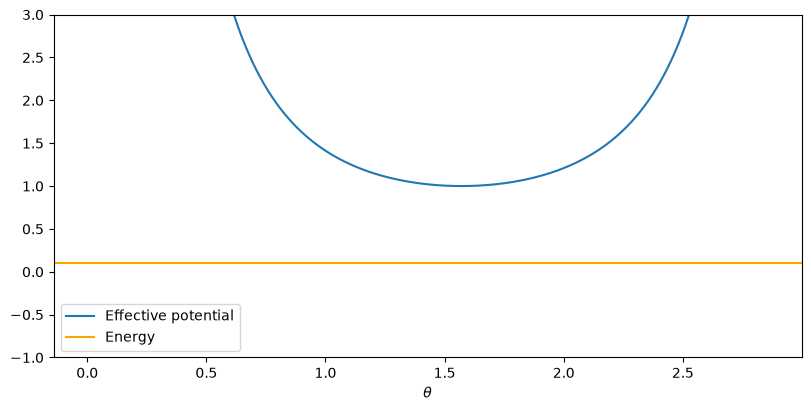

interactive(children=(FloatSlider(value=0.0, description='a', max=10.0), FloatSlider(value=0.0, description='b…

In [9]:
from scipy.optimize import brentq
def show_potential(a=0.,b=0.,e0=.1):
    x=np.linspace(.002,np.pi/1.1,1500)
    def potential(q): return a*(np.cos(q)-1)+(1-b*np.cos(q))**2/np.sin(q)**2
    y=potential(x); roots=[]
    for lo,hi,flo,fhi in zip(x[:-1],x[1:],y[:-1]-e0,y[1:]-e0):
        if flo*fhi<0: roots.append(brentq(lambda q:potential(q)-e0,lo,hi))
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    ax.plot(x,y,label='Effective potential'); ax.axhline(e0,color='orange',label='Energy')
    ax.plot(roots,[e0]*len(roots),'ro'); ax.set(xlabel=r'$\theta$',ylim=(min(-1,float(y.min())-.1),max(3,e0+.5)))
    ax.legend(); plt.show()
show_potential()
potential_controls=widgets.interactive(show_potential,a=widgets.FloatSlider(min=0,max=10,step=.1,value=0),
    b=widgets.FloatSlider(min=0,max=10,step=.1,value=0),e0=widgets.FloatSlider(min=.1,max=2,step=.05,value=.1))
display(potential_controls)

Introducing the variable u = cosθ the analysis of motion reduces to consideration of function

$$
t = \tau {\int }_{{u}_{0}}^{\cos{\theta} }\frac{d u}{\sqrt{\left(1-c u\right)\left(1-{u}^{2}\right)-{\left(a-b u\right)}^{2}}},\\ {\tau }^{-2}=\frac{2E-{M}_{3}^{2}/{I}_{3}}{{\widetilde{I}}_{1}}, c=\frac{2m {l}^{2}}{{\widetilde{I}}_{1}}{\omega }_{0}^{2}{\tau }^{2}, a=\frac{{M}_{z}}{{\widetilde{I}}_{1}}\tau , b=\frac{{M}_{3}}{{\widetilde{I}}_{1}}\tau
$$

There are three characteristic types of motion depending on the sign of $\dot{\varphi }$ which depends on the value:

$$
{M}_{z}-{M}_{3}\cos{\theta}
$$

since

$$
\dot{\varphi }=\frac{{M}_{z}-{M}_{3} \cos{\theta} }{{\widetilde{I}}_{1}\sin^{2}{\theta} }
$$

If  ${M}_{z}-{M}_{3} \cos{\theta} $ > 0 then we have monotonic precession around Z axis and periodic nutation of θ (type a). Type b occurs when ${M}_{z}-{M}_{3} \cos{\theta} $ changes sign in the interval ${\theta }_{\text{min},}{\theta }_{\text{max}}$. Type c is for the case when ${M}_{z}-{M}_{3} \cos{{\theta}_{\text{min}}}=0$



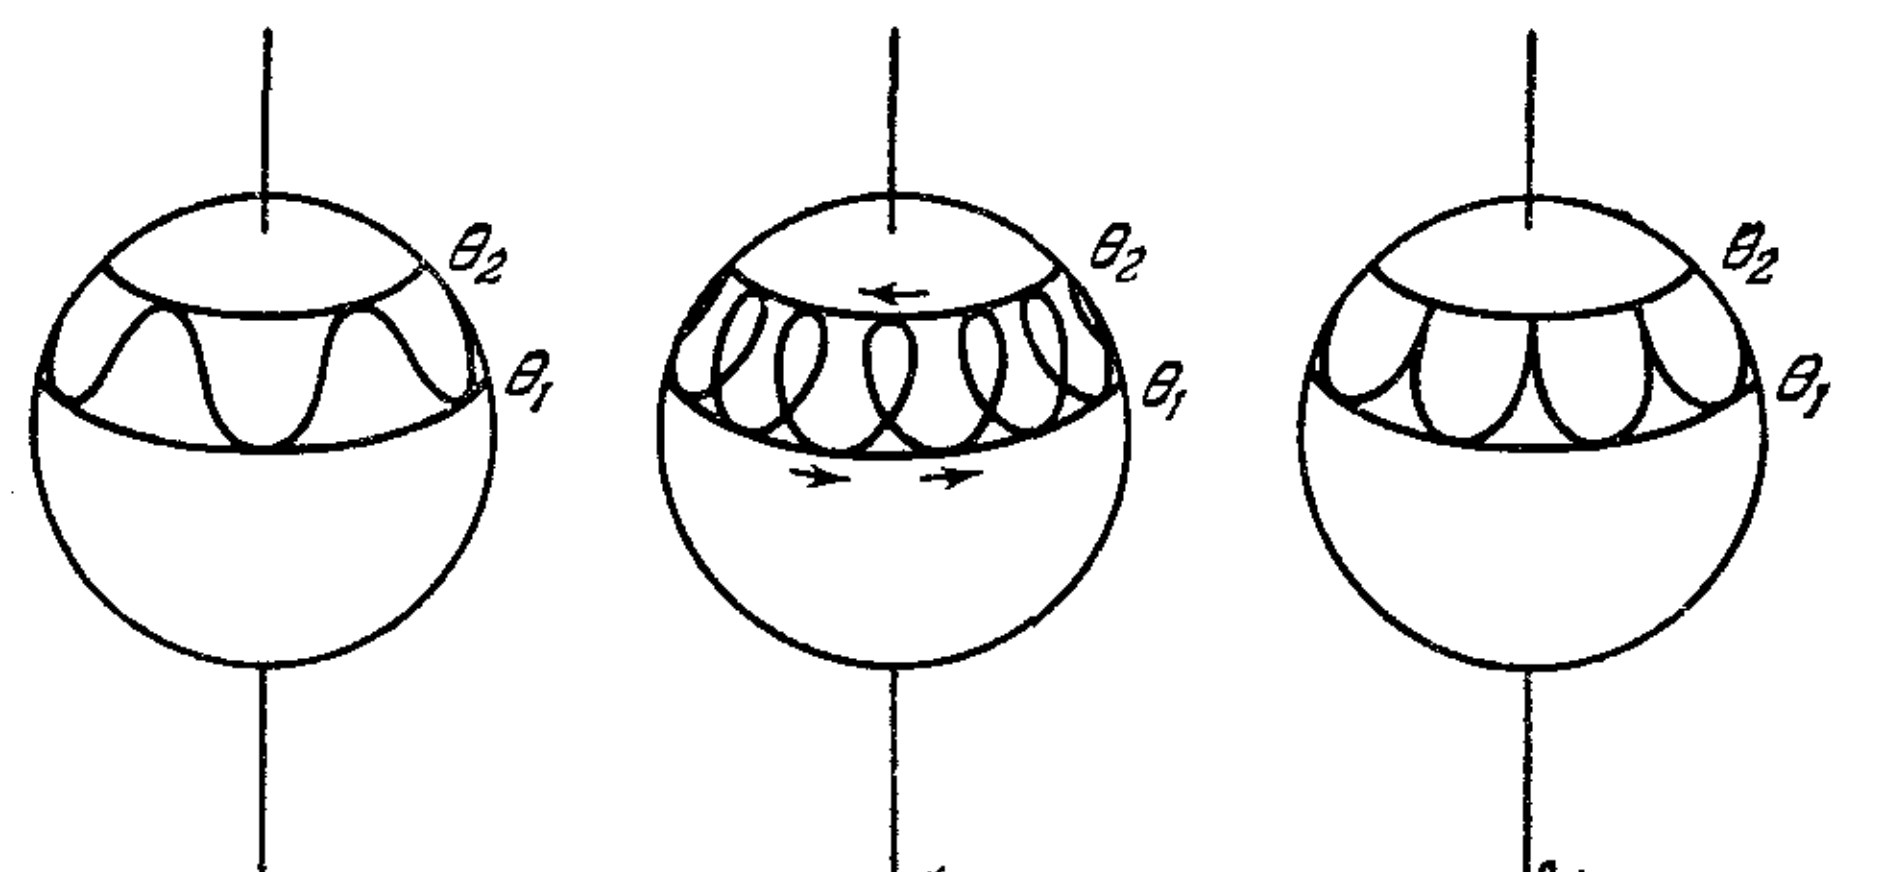


Three types of Lagrange top motion a,b,c
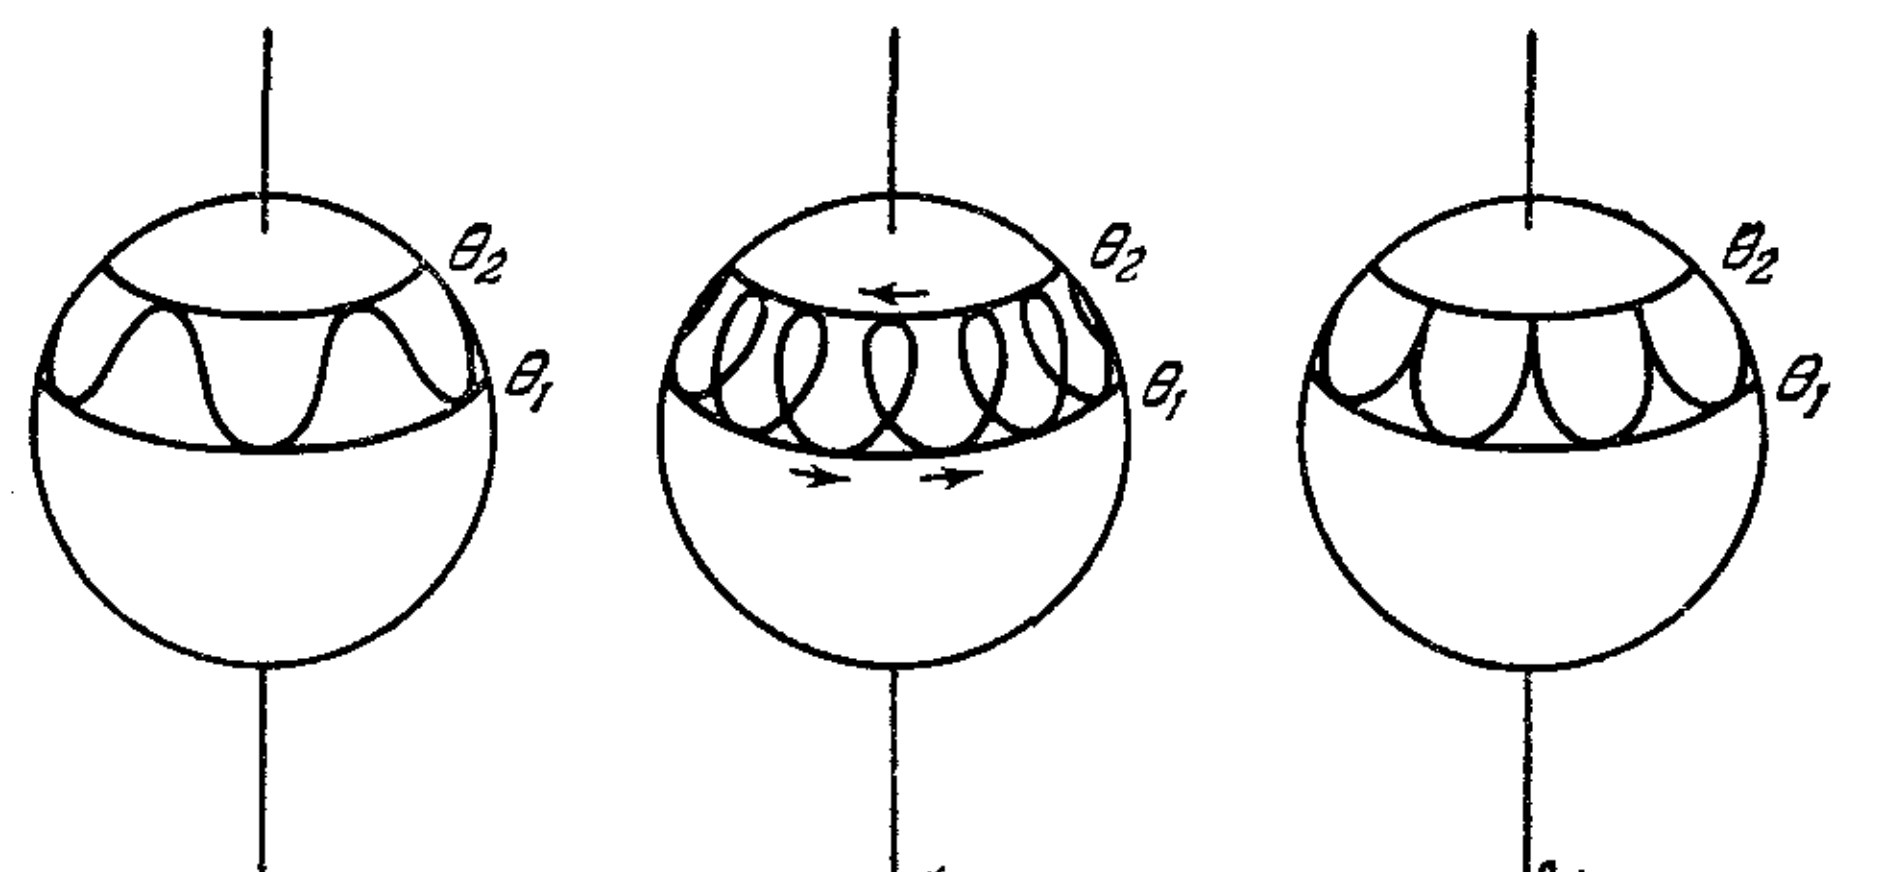

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)